In [9]:
# Clonar el repositorio RepoRT si no está presente
!git clone https://github.com/michaelwitting/RepoRT.git

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Explorar la estructura para ubicar el archivo de datos principal (ej. .csv)
print("Contenido del repositorio:", os.listdir('RepoRT'))

Cloning into 'RepoRT'...
remote: Enumerating objects: 51705, done.
remote: Counting objects: 100% (1575/1575), done.
remote: Compressing objects: 100% (522/522), done.
remote: Total 51705 (delta 1295), reused 1053 (delta 1053), pack-reused 50130 (from 3)
Receiving objects: 100% (51705/51705), 342.35 MiB | 23.80 MiB/s, done.
Resolving deltas: 100% (36794/36794), done.
Updating files: 100% (9387/9387), done.
Contenido del repositorio: ['.github', 'processed_data', 'example', 'LICENSE', 'DataDescription.html', '.gitignore', 'resources', 'raw_data', '.Rprofile', 'renv', 'README.md', 'renv.lock', '.gitattributes', 'README.html', 'RtPredTrainingData.Rproj', 'Dockerfile', '.git', 'DataDescription.md', 'scripts']


In [12]:
import glob

# Buscamos cualquier archivo dentro de RepoRT para ver qué extensiones maneja
todos_los_archivos = glob.glob('RepoRT/**/*', recursive=True)

# Filtramos para ver qué tipos de archivos hay (excluyendo carpetas)
extensiones = set(f.split('.')[-1] for f in todos_los_archivos if '.' in f)
print("Extensiones de archivos encontradas en RepoRT:", extensiones)

# Busquemos si hay archivos .RData, .rds o txt
archivos_datos = [f for f in todos_los_archivos if f.endswith(('.rdata', '.rds', '.txt', '.csv', '.tsv', '.parquet'))]
print("\nArchivos de datos principales encontrados:", archivos_datos[:15])

Extensiones de archivos encontradas en RepoRT: {'tsv', 'lock', 'bk', 'old', 'R', 'md', 'jar', 'py', 'yaml', 'html', 'txt', 'Rproj', 'pdf', 'dcf'}

Archivos de datos principales encontrados: ['RepoRT/processed_data/studies.tsv', 'RepoRT/processed_data/0402/0402_descriptors_isomeric_success.tsv', 'RepoRT/processed_data/0402/0402_fingerprints_pubchem_canonical_success.tsv', 'RepoRT/processed_data/0402/0402_fingerprints_ecfp6_isomeric_success.tsv', 'RepoRT/processed_data/0402/0402_info.tsv', 'RepoRT/processed_data/0402/0402_fingerprints_maccs_canonical_success.tsv', 'RepoRT/processed_data/0402/0402_fingerprints_pubchem_isomeric_success.tsv', 'RepoRT/processed_data/0402/0402_descriptors_canonical_success.tsv', 'RepoRT/processed_data/0402/0402_fingerprints_ecfp6_canonical_success.tsv', 'RepoRT/processed_data/0402/0402_metadata.tsv', 'RepoRT/processed_data/0402/0402_rtdata_canonical_success.tsv', 'RepoRT/processed_data/0402/0402_validation_qspr_outliers.tsv', 'RepoRT/processed_data/0402/0402_

In [13]:
import glob
import pandas as pd

# 1. Buscamos todos los archivos de datos de retención (rtdata) en formato tsv dentro de processed_data
archivos_rt = glob.glob('RepoRT/processed_data/**/*rtdata*.tsv', recursive=True)

print(f"¡Se encontraron {len(archivos_rt)} estudios con datos de retención en el repositorio!")

# 2. Vamos a cargar y consolidar una muestra grande de estos estudios (por ejemplo, los primeros 20 o 50 para empezar a probar)
lista_dfs = []

for archivo in archivos_rt[:30]: # Puedes aumentar este número progresivamente
    try:
        df_temp = pd.read_csv(archivo, sep='\t', low_memory=False)
        # Opcional: Agregar una columna para identificar el estudio de origen basado en la ruta
        estudio_id = archivo.split('/')[-2]
        df_temp['study_id'] = estudio_id
        lista_dfs.append(df_temp)
    except Exception as e:
        print(f"Error al leer {archivo}: {e}")

# 3. Fusionamos todo en un gran DataFrame global
if len(lista_dfs) > 0:
    df_global_tsv = pd.concat(lista_dfs, ignore_index=True)
    print("\n¡Dataset global consolidado con éxito desde archivos TSV!")
    print(f"Dimensiones del dataset masivo: {df_global_tsv.shape[0]} filas y {df_global_tsv.shape[1]} columnas.")
    display(df_global_tsv.head(3))
else:
    print("No se pudieron cargar los archivos TSV.")

¡Se encontraron 1242 estudios con datos de retención en el repositorio!

¡Dataset global consolidado con éxito desde archivos TSV!
Dimensiones del dataset masivo: 4515 filas y 16 columnas.


,id,name,formula,rt,smiles.std,inchi.std,inchikey.std,classyfire.kingdom,classyfire.superclass,classyfire.class,classyfire.subclass,classyfire.level5,classyfire.level6,comment,study_id,status
0,0402_00001,NaN,C6H18O24P6,0.588286,C1(C(C(C(C(C1OP(=O)(O)O)OP(=O)(O)O)OP(=O)(O)O)...,"InChI=1S/C6H18O24P6/c7-31(8,9)25-1-2(26-32(10,...",IMQLKJBTEOYOSI-UHFFFAOYSA-N,Organic compounds (CHEMONTID:0000000),Organic oxygen compounds (CHEMONTID:0004603),Organooxygen compounds (CHEMONTID:0000323),Alcohols and polyols (CHEMONTID:0000129),Cyclic alcohols and derivatives (CHEMONTID:000...,Cyclitols and derivatives (CHEMONTID:0002509),NaN,0402,NaN
1,0402_00002,NaN,C10H15N5O10P2,0.620808,C1=NC(=C2C(=N1)N(C=N2)C3C(C(C(O3)COP(=O)(O)O)O...,InChI=1S/C10H15N5O10P2/c11-8-5-9(13-2-12-8)15(...,WHTCPDAXWFLDIH-UHFFFAOYSA-N,Organic compounds (CHEMONTID:0000000),"Nucleosides, nucleotides, and analogues (CHEMO...",Purine nucleotides (CHEMONTID:0001506),Purine ribonucleotides (CHEMONTID:0001544),Purine ribonucleoside bisphosphates (CHEMONTID...,"Purine ribonucleoside 3',5'-bisphosphates (CHE...",NaN,0402,NaN
2,0402_00003,NaN,C9H16N3O14P3,0.623686,C1=CN(C(=O)N=C1N)C2C(C(C(O2)COP(=O)(O)OP(=O)(O...,InChI=1S/C9H16N3O14P3/c10-5-1-2-12(9(15)11-5)8...,PCDQPRRSZKQHHS-UHFFFAOYSA-N,Organic compounds (CHEMONTID:0000000),"Nucleosides, nucleotides, and analogues (CHEMO...",Pyrimidine nucleotides (CHEMONTID:0001509),Pyrimidine ribonucleotides (CHEMONTID:0002147),Pyrimidine ribonucleoside triphosphates (CHEMO...,NA (NA),NaN,0402,NaN


In [14]:
# Buscamos los archivos de descriptores (descriptors) correspondientes a los estudios
archivos_desc = glob.glob('RepoRT/processed_data/**/*descriptors*.tsv', recursive=True)
print(f"Se encontraron {len(archivos_desc)} archivos de descriptores moleculares.")

# Cargamos un archivo de descriptores de ejemplo para ver su estructura y combinarlo
if len(archivos_desc) > 0:
    df_desc_ejemplo = pd.read_csv(archivos_desc[0], sep='\t', low_memory=False)
    print("\nEstructura de los descriptores moleculares:")
    print(f"Dimensiones: {df_desc_ejemplo.shape}")
    display(df_desc_ejemplo.head(3))

Se encontraron 838 archivos de descriptores moleculares.

Estructura de los descriptores moleculares:
Dimensiones: (257, 287)


,id,Wlambda1.unity,Wlambda2.unity,Wlambda3.unity,Wnu1.unity,Wnu2.unity,Wgamma1.unity,Wgamma2.unity,Wgamma3.unity,Weta1.unity,...,LOBMIN,GRAV.1,GRAV.2,GRAV.3,GRAVH.1,GRAVH.2,GRAVH.3,GRAV.4,GRAV.5,GRAV.6
0,0402_00002,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,0402_00003,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,0402_00004,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [15]:
import glob
import pandas as pd

# 1. Buscamos todos los archivos de retención y de descriptores
archivos_rt = glob.glob('RepoRT/processed_data/**/*rtdata*.tsv', recursive=True)
archivos_desc = glob.glob('RepoRT/processed_data/**/*descriptors*.tsv', recursive=True)

# Creamos diccionarios para indexarlos rápido por el código del estudio (ej. '0402')
dict_desc = {}
for desc_path in archivos_desc:
    # Extraemos el study_id de la ruta o del nombre del archivo
    study_id = desc_path.split('/')[-2]
    dict_desc[study_id] = desc_path

lista_estudios_fusionados = []

# 2. Iteramos sobre los estudios de retención y buscamos su par de descriptores
for rt_path in archivos_rt[:30]: # Empezamos con los primeros 30 estudios para probar
    study_id = rt_path.split('/')[-2]

    if study_id in dict_desc:
        try:
            # Leemos ambos archivos TSV
            df_rt = pd.read_csv(rt_path, sep='\t', low_memory=False)
            df_desc = pd.read_csv(dict_desc[study_id], sep='\t', low_memory=False)

            # Unimos ambas tablas usando la columna 'id' que comparten
            if 'id' in df_rt.columns and 'id' in df_desc.columns:
                df_merged = pd.merge(df_rt, df_desc, on='id', how='inner')
                df_merged['study_id'] = study_id
                lista_estudios_fusionados.append(df_merged)
        except Exception as e:
            print(f"Error procesando el estudio {study_id}: {e}")

# 3. Consolidamos el gran dataset global cruzado
if len(lista_estudios_fusionados) > 0:
    df_global_qsr = pd.concat(lista_estudios_fusionados, ignore_index=True)
    print("\n¡Fusión completada con éxito!")
    print(f"Dataset masivo QSRR consolidado: {df_global_qsr.shape[0]} filas (moléculas) y {df_global_qsr.shape[1]} columnas (descriptores + retención).")
    display(df_global_qsr.head(3))
else:
    print("No se pudieron fusionar los estudios.")


¡Fusión completada con éxito!
Dataset masivo QSRR consolidado: 3893 filas (moléculas) y 302 columnas (descriptores + retención).


,id,name,formula,rt,smiles.std,inchi.std,inchikey.std,classyfire.kingdom,classyfire.superclass,classyfire.class,...,GRAV.2,GRAV.3,GRAVH.1,GRAVH.2,GRAVH.3,GRAV.4,GRAV.5,GRAV.6,study_id,status
0,0402_00001,NaN,C6H18O24P6,0.588286,C1(C(C(C(C(C1OP(=O)(O)O)OP(=O)(O)O)OP(=O)(O)O)...,"InChI=1S/C6H18O24P6/c7-31(8,9)25-1-2(26-32(10,...",IMQLKJBTEOYOSI-UHFFFAOYSA-N,Organic compounds (CHEMONTID:0000000),Organic oxygen compounds (CHEMONTID:0004603),Organooxygen compounds (CHEMONTID:0000323),...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0402,NaN
1,0402_00002,NaN,C10H15N5O10P2,0.620808,C1=NC(=C2C(=N1)N(C=N2)C3C(C(C(O3)COP(=O)(O)O)O...,InChI=1S/C10H15N5O10P2/c11-8-5-9(13-2-12-8)15(...,WHTCPDAXWFLDIH-UHFFFAOYSA-N,Organic compounds (CHEMONTID:0000000),"Nucleosides, nucleotides, and analogues (CHEMO...",Purine nucleotides (CHEMONTID:0001506),...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0402,NaN
2,0402_00003,NaN,C9H16N3O14P3,0.623686,C1=CN(C(=O)N=C1N)C2C(C(C(O2)COP(=O)(O)OP(=O)(O...,InChI=1S/C9H16N3O14P3/c10-5-1-2-12(9(15)11-5)8...,PCDQPRRSZKQHHS-UHFFFAOYSA-N,Organic compounds (CHEMONTID:0000000),"Nucleosides, nucleotides, and analogues (CHEMO...",Pyrimidine nucleotides (CHEMONTID:0001509),...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0402,NaN


In [16]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, r2_score

# 1. Identificamos la columna objetivo (tiempo de retención, que suele llamarse 'rt' o similar)
# Busquemos columnas que contengan 'rt' o el valor numérico de retención
columna_rt = [c for c in df_global_qsr.columns if 'rt' in c.lower()][0] # O ajusta el nombre exacto si lo conoces
print(f"Columna objetivo detectada para el tiempo de retención: {columna_rt}")

# 2. Seleccionamos las características (excluyendo metadatos, id, fórmulas, smiles, etc.)
# Tomamos únicamente las columnas numéricas que actúan como descriptores
X = df_global_qsr.select_dtypes(include=['float64', 'int64']).drop(columns=[columna_rt], errors='ignore')
y = df_global_qsr[columna_rt]

# Eliminamos filas donde la variable objetivo sea nula (NaN)
filas_validas = y.notna()
X = X[filas_validas]
y = y[filas_validas]

print(f"Dimensiones finales para entrenamiento - X: {X.shape}, y: {y.shape}")

# 3. Construimos el Pipeline masivo con VarianceThreshold + Imputador + Random Forest
pipeline_masivo = Pipeline([
    ('var_thresh', VarianceThreshold(threshold=0.01)), # Elimina descriptores constantes
    ('imputer', SimpleImputer(strategy='median')),     # Rellena nulos
    ('model', RandomForestRegressor(n_estimators=50, random_state=42, n_jobs=-1))
])

# 4. División de datos y entrenamiento
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("\nEntrenando modelo con el dataset masivo de RepoRT...")
pipeline_masivo.fit(X_train, y_train)

# 5. Evaluación
y_pred = pipeline_masivo.predict(X_test)
r2 = r2_score(y_test, y_pred)
print(f"¡Modelo entrenado con éxito a gran escala!")
print(f"R² Score en conjunto de prueba: {r2:.4f}")

Columna objetivo detectada para el tiempo de retención: rt
Dimensiones finales para entrenamiento - X: (3893, 286), y: (3893,)

Entrenando modelo con el dataset masivo de RepoRT...


/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_variance_threshold.py:114: RuntimeWarning: Degrees of freedom <= 0 for slice.
  self.variances_ = np.nanvar(X, axis=0)


¡Modelo entrenado con éxito a gran escala!
R² Score en conjunto de prueba: 0.6014


In [17]:
from sklearn.model_selection import RepeatedKFold, cross_val_score
import numpy as np

# Definimos la validación cruzada repetida (ej. 5 particiones, 3 repeticiones)
cv = RepeatedKFold(n_splits=5, n_repeats=3, random_state=42)

# Evaluamos el pipeline completo con validación cruzada
scores = cross_val_score(pipeline_masivo, X, y, scoring='r2', cv=cv, n_jobs=-1)

print(f"R² scores en validación cruzada: {scores}")
print(f"R² promedio: {scores.mean():.4f} (+/- {scores.std():.4f})")

R² scores en validación cruzada: [0.617847   0.60629678 0.65670913 0.60200301 0.6239617  0.55876906
 0.66131788 0.62935861 0.63433242 0.64833174 0.57855332 0.61867605
 0.64507304 0.67209443 0.56320607]
R² promedio: 0.6211 (+/- 0.0334)


In [18]:
from sklearn.model_selection import RandomizedSearchCV

# Definimos los hiperparámetros a explorar
param_dist = {
    'model__n_estimators': [50, 100, 200],
    'model__max_depth': [None, 10, 20, 30],
    'model__min_samples_split': [2, 5, 10]
}

# Buscamos la mejor combinación usando validación cruzada
search = RandomizedSearchCV(
    estimator=pipeline_masivo,
    param_distributions=param_dist,
    n_iter=5,
    cv=3,
    scoring='r2',
    random_state=42,
    n_jobs=-1
)

search.fit(X_train, y_train)

print(f"Mejores hiperparámetros encontrados: {search.best_params_}")
print(f"Mejor R² en entrenamiento con optimización: {search.best_score_:.4f}")

/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_variance_threshold.py:114: RuntimeWarning: Degrees of freedom <= 0 for slice.
  self.variances_ = np.nanvar(X, axis=0)


Mejores hiperparámetros encontrados: {'model__n_estimators': 100, 'model__min_samples_split': 10, 'model__max_depth': 10}
Mejor R² en entrenamiento con optimización: 0.5973


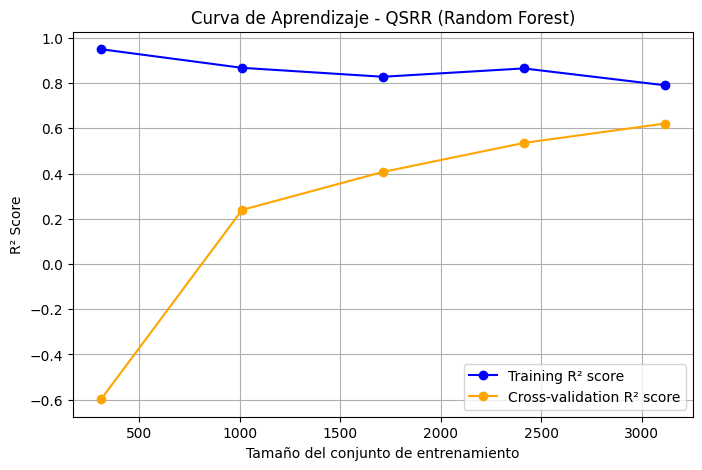

In [23]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import RepeatedKFold, learning_curve

# Usamos la validación cruzada repetida que ya definiste o creamos una para la curva
cv_reg = RepeatedKFold(n_splits=5, n_repeats=3, random_state=42)

train_sizes, train_scores, val_scores = learning_curve(
    estimator=pipeline_masivo, # Tu pipeline real
    X=X,
    y=y,
    cv=cv_reg,
    scoring='r2',  # Métrica de regresión
    n_jobs=-1,
    train_sizes=np.linspace(0.1, 1.0, 5)
)

train_mean = np.mean(train_scores, axis=1)
val_mean = np.mean(val_scores, axis=1)

# Graficar curva de aprendizaje
plt.figure(figsize=(8, 5))
plt.plot(train_sizes, train_mean, label='Training R² score', marker='o', color='blue')
plt.plot(train_sizes, val_mean, label='Cross-validation R² score', marker='o', color='orange')
plt.xlabel('Tamaño del conjunto de entrenamiento')
plt.ylabel('R² Score')
plt.title('Curva de Aprendizaje - QSRR (Random Forest)')
plt.legend(loc='best')
plt.grid(True)
plt.show()

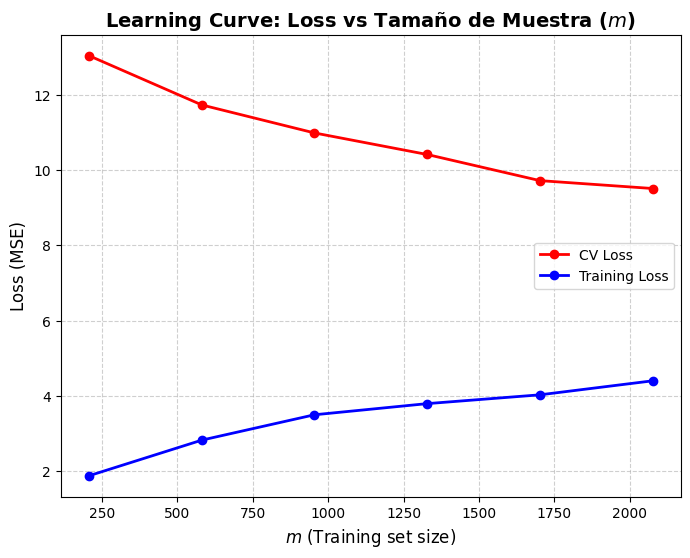

In [27]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve

# Generamos tamaños fraccionarios para el conjunto de entrenamiento (m)
train_sizes_fraction = np.linspace(0.1, 1.0, 6)

train_sizes_abs, train_scores, val_scores = learning_curve(
    estimator=pipeline_masivo,
    X=X_train,
    y=y_train,
    cv=3,
    scoring='neg_mean_squared_error', # Usamos MSE como Loss
    n_jobs=-1,
    train_sizes=train_sizes_fraction
)

# Convertimos los scores negativos a Loss positiva (MSE)
train_loss_mean = -np.mean(train_scores, axis=1)
val_loss_mean = -np.mean(val_scores, axis=1)

# Graficando Loss vs m (Training set size)
plt.figure(figsize=(8, 6))
plt.plot(train_sizes_abs, val_loss_mean, label='CV Loss', color='red', marker='o', linewidth=2)
plt.plot(train_sizes_abs, train_loss_mean, label='Training Loss', color='blue', marker='o', linewidth=2)

plt.xlabel('$m$ (Training set size)', fontsize=12)
plt.ylabel('Loss (MSE)', fontsize=12)
plt.title('Learning Curve: Loss vs Tamaño de Muestra ($m$)', fontsize=14, fontweight='bold')
plt.legend(loc='center right')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

In [24]:
from scipy.stats import wilcoxon
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import Ridge

# Definimos un segundo modelo para comparar (ej. Regresión Ridge)
pipeline_ridge = Pipeline([
    ('var_thresh', pipeline_masivo.named_steps['var_thresh']),
    ('imputer', pipeline_masivo.named_steps['imputer']),
    ('model', Ridge(alpha=1.0))
])

# Obtenemos los scores fold por fold con RepeatedKFold
scores_rf = cross_val_score(pipeline_masivo, X, y, scoring='r2', cv=cv_reg, n_jobs=-1)
scores_ridge = cross_val_score(pipeline_ridge, X, y, scoring='r2', cv=cv_reg, n_jobs=-1)

# Aplicar test de Wilcoxon
stat, p_value = wilcoxon(scores_rf, scores_ridge)

print(f"Estadístico W: {stat:.4f}")
print(f"P-value: {p_value:.5f}")

alpha = 0.05
if p_value < alpha:
    print("Conclusión: La diferencia de rendimiento entre Random Forest y Ridge es estadísticamente significativa.")
else:
    print("Conclusión: No hay evidencia estadística suficiente para afirmar que un modelo supera al otro.")

Estadístico W: 0.0000
P-value: 0.00006
Conclusión: La diferencia de rendimiento entre Random Forest y Ridge es estadísticamente significativa.


/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Wlambda1.unity' 'Wlambda2.unity' 'Wlambda3.unity' 'Wnu1.unity'
 'Wnu2.unity' 'Wgamma1.unity' 'Wgamma2.unity' 'Wgamma3.unity'
 'Weta1.unity' 'Weta2.unity' 'Weta3.unity' 'WT.unity' 'WA.unity'
 'WV.unity' 'WK.unity' 'WG.unity' 'WD.unity' 'VABC' 'geomShape' 'PPSA.1'
 'PPSA.2' 'PPSA.3' 'PNSA.1' 'PNSA.2' 'PNSA.3' 'DPSA.1' 'DPSA.2' 'DPSA.3'
 'FPSA.1' 'FPSA.2' 'FPSA.3' 'FNSA.1' 'FNSA.2' 'FNSA.3' 'WPSA.1' 'WPSA.2'
 'WPSA.3' 'WNSA.1' 'WNSA.2' 'WNSA.3' 'RPCG' 'RNCG' 'RPCS' 'RNCS' 'THSA'
 'TPSA' 'RHSA' 'RPSA' 'MOMI.X' 'MOMI.Y' 'MOMI.Z' 'MOMI.XY' 'MOMI.XZ'
 'MOMI.YZ' 'MOMI.R' 'LOBMAX' 'LOBMIN' 'GRAV.1' 'GRAV.2' 'GRAV.3' 'GRAVH.1'
 'GRAVH.2' 'GRAVH.3' 'GRAV.4' 'GRAV.5' 'GRAV.6']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' 

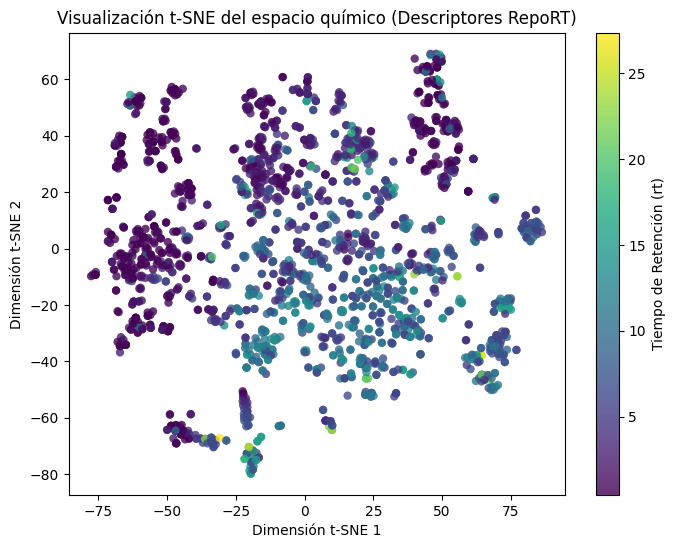

In [26]:
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Imputamos los valores nulos (usando la misma lógica de tu pipeline)
imputer_tsne = SimpleImputer(strategy='median')
X_imputed = imputer_tsne.fit_transform(X)

# 2. Tomamos una muestra aleatoria segura de los datos
n_samples = min(2000, X_imputed.shape[0])
rng = np.random.RandomState(42)
indices = rng.choice(X_imputed.shape[0], size=n_samples, replace=False)

X_sample = X_imputed[indices]
y_sample = y.iloc[indices]

# 3. Normalizamos los descriptores
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_sample)

# 4. Aplicamos t-SNE
tsne = TSNE(n_components=2, random_state=42, perplexity=30, n_iter=1000)
X_tsne = tsne.fit_transform(X_scaled)

# 5. Graficar
plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    X_tsne[:, 0],
    X_tsne[:, 1],
    c=y_sample,
    cmap='viridis',
    alpha=0.8,
    edgecolor='none'
)
plt.colorbar(scatter, label='Tiempo de Retención (rt)')
plt.title('Visualización t-SNE del espacio químico (Descriptores RepoRT)')
plt.xlabel('Dimensión t-SNE 1')
plt.ylabel('Dimensión t-SNE 2')
plt.show()

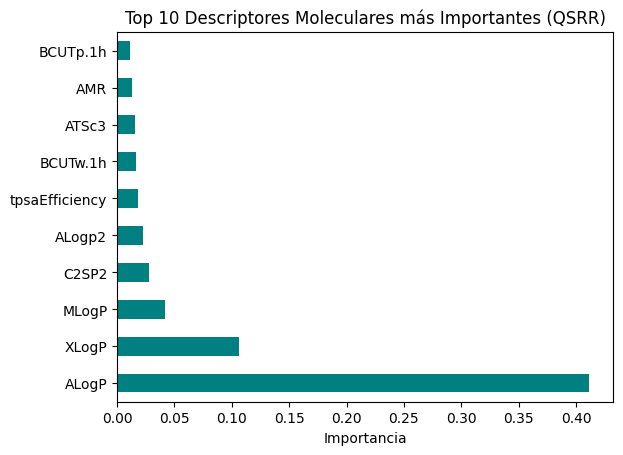

In [19]:
import pandas as pd
import matplotlib.pyplot as plt

# Extraemos el modelo entrenado y los nombres de las características post-variance threshold
modelo_rf = pipeline_masivo.named_steps['model']
selector_var = pipeline_masivo.named_steps['var_thresh']
features_validas = X.columns[selector_var.get_support()]

# Creamos un DataFrame con la importancia
importancias = pd.Series(modelo_rf.feature_importances_, index=features_validas)
importancias.nlargest(10).plot(kind='barh', color='teal')
plt.title("Top 10 Descriptores Moleculares más Importantes (QSRR)")
plt.xlabel("Importancia")
plt.show()

In [22]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import RepeatedStratifiedKFold, learning_curve

# Configurar validación cruzada repetida estratificada
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)

# REEMPLAZA 'tu_modelo' por el nombre real de tu variable (ej. pipeline, clf, rf_model, etc.)
mi_estimador = pipeline  # <--- Cambia esto por tu variable de modelo/pipeline

# Calcular curva de aprendizaje
train_sizes, train_scores, val_scores = learning_curve(
    estimator=mi_estimador,
    X=X,
    y=y,
    cv=cv,
    scoring='accuracy',  # Cambiar a 'neg_mean_squared_error' si es regresión
    n_jobs=-1,
    train_sizes=np.linspace(0.1, 1.0, 5)
)

train_mean = np.mean(train_scores, axis=1)
val_mean = np.mean(val_scores, axis=1)

# Graficar curva de aprendizaje
plt.figure(figsize=(8, 5))
plt.plot(train_sizes, train_mean, label='Training score', marker='o', color='blue')
plt.plot(train_sizes, val_mean, label='Cross-validation score', marker='o', color='orange')
plt.xlabel('Tamaño del conjunto de entrenamiento')
plt.ylabel('Score')
plt.title('Curva de Aprendizaje del Modelo')
plt.legend(loc='best')
plt.grid(True)
plt.show()

NameError: name 'pipeline' is not defined